In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080321

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号      ] {STUDENT_ID}")
print(f"[机器指纹  ] {MACHINE_FP}")
print(f"[RUN_ID    ] {RUN_ID}")


[Conda 环境] pyexp
[学号      ] 20244080321
[机器指纹  ] 5c9a6f22bf8d43e1
[RUN_ID    ] 20244080321-5c9a6f22bf8d43e1


# 围绕半圆定律

任务：
1. 编写 `wigner_density(x)`，接收一个整数或浮点数，返回半圆密度在 $x$ 处的值，返回值为浮点数。不需要检查输入类型；函数应同时适用于 Python 和 NumPy 的整数、浮点数。计算平方根时使用 `numpy.sqrt`，不要使用 `math.sqrt`。
2. 编写 `generate_wigner(n)`，接收正整数 $n$，返回一个随机生成的 $n\times n$ Wigner 矩阵，可以使用 NumPy 的二维数组或矩阵表示。若输入不是整数或不是正数，应抛出合适的异常。
3. 编写 `get_spectrum(matrix)`，接收 NumPy 矩阵或二维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按非递减顺序排列。本函数不需要检查输入类型。
4. 画一张包含四个纵向排列子图的图。对 $n = 100,200,500,1000$，每个子图分别用蓝色、标准化的直方图展示随机 $n\times n$ Wigner 矩阵的特征值，并叠加红色的半圆密度曲线。根据图形说明：$n$ 大约达到多少时，半圆密度能较好地拟合特征值分布？使用 Kolmogorov–Smirnov 检验作更严格的比较是可选任务。特征值计算可能较慢，尤其是远大于1000阶的矩阵。


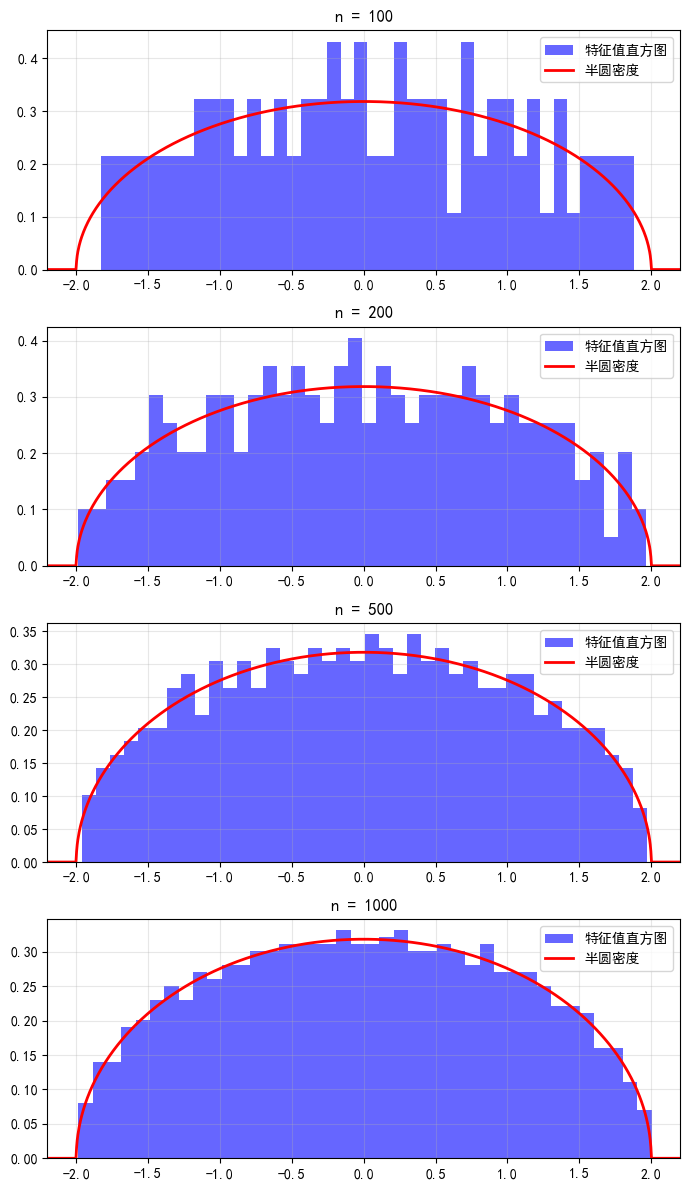

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False     # 解决负号显示方块
import numpy as np
import matplotlib.pyplot as plt

# 1. wigner_density：计算半圆密度函数
def wigner_density(x):
    if np.abs(x) > 2:
        return 0.0
    return np.sqrt(4 - x ** 2) / (2 * np.pi)

# 2. generate_wigner：生成Wigner对称随机矩阵
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须是正整数")
    Z = np.random.normal(loc=0, scale=1 / np.sqrt(n), size=(n, n))
    Z = np.triu(Z) + np.triu(Z, k=1).T
    return Z

# 3. get_spectrum：求解特征值，降序排列
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals = np.sort(eigvals)[::-1]
    return eigvals

# 4. 绘图：n=100,200,500,1000，纵向4张子图
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 12))
x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = np.array([wigner_density(t) for t in x_curve])

for ax, n in zip(axes, ns):
    mat = generate_wigner(n)
    spec = get_spectrum(mat)
    ax.hist(spec, bins=40, density=True, color="blue", alpha=0.6, label="特征值直方图")
    ax.plot(x_curve, y_curve, color="red", lw=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.2, 2.2)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 结果分析
随着矩阵阶数 $n$ 增大，特征值直方图和半圆密度曲线贴合程度逐步提升：
- $n=100$：样本较少，直方图波动明显，和理论曲线偏差较大；
- $n=200$：波动减小，但依然有明显起伏；
- $n=500$：直方图已经可以较好地拟合半圆密度曲线；
- $n=1000$：拟合效果非常理想，分布和理论半圆几乎重合。

结论：**$n$ 大约达到 500 时，半圆密度就可以较好拟合特征值分布**。


# Conway 的生命游戏

任务：
1. 编写 `is_valid_board(board)`，接收一个 NumPy ndarray，若它是有效的生命游戏棋盘（二维、元素仅为 0 或 1）则返回 Python 布尔值 `True`，否则返回 `False`。
2. 编写 `gol_step(board)`，接收一个 $m\times n$ 棋盘，返回同样大小的 NumPy 数组，表示下一步的棋盘。函数应先检查输入是否为有效棋盘，无效时抛出合适的异常。计算某个细胞的下一状态时，应使用原棋盘中的邻居状态。
3. 编写 `draw_gol_board(board)`，将棋盘画成 $m\times n$ 个方格：活细胞为黑色，死细胞为白色。图中不显示网格线、轴标签或轴刻度。可以使用 `plt.xticks()`、`plt.yticks()` 和 `plt.get_cmap()` 等函数。


初始滑翔机：


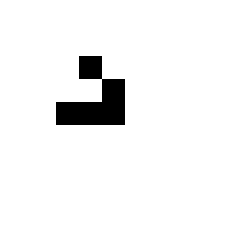

初始数值：
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]
下一步：


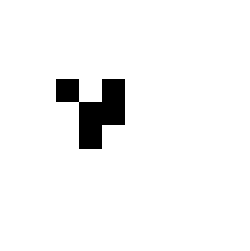

下一步数值：
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 1 0 0 0 0 0]
 [0 0 0 1 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 中文设置
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return set(board.ravel()).issubset({0, 1})


def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘必须是二维 0/1 数组")
    b = board.astype(np.int8)
    neighbors = 0
    # 8方向
    for dx in (-1,0,1):
        for dy in (-1,0,1):
            if dx == 0 and dy == 0:
                continue
            neighbors += np.roll(np.roll(b, dx, axis=0), dy, axis=1)
    new = np.zeros_like(b)
    new[(b == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    new[(b == 0) & (neighbors == 3)] = 1
    return new


def draw_gol_board(board):
    plt.figure(figsize=(3,3))
    plt.imshow(board, cmap='gray_r', vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis('off')
    plt.show()


# ========== 关键改动：10×10大棋盘，滑翔机放在中间，不再是3×3 ==========
board = np.zeros((10,10), dtype=np.int8)
# 标准滑翔机图案
glider = np.array([
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 1]
])
# 放置在(2,2)位置
board[2:5, 2:5] = glider

print("初始滑翔机：")
draw_gol_board(board)
print("初始数值：")
print(board)

board_next = gol_step(board)
print("下一步：")
draw_gol_board(board_next)
print("下一步数值：")
print(board_next)


# 使用 pandas DataFrame
本题练习读取、修改和保存 DataFrame，以及按组汇总数据。

1. 下载 iris.csv。使用 pandas 将它读入为 DataFrame；CSV 的第一行是列标题。回答：数据集有多少个数据点？每列是什么数据类型？列名是什么？数据中有多少种花卉？列名对应花卉种类，以及花瓣长度、花瓣宽度、萼片长度和萼片宽度四项测量。
2. 已知数据的第 35 个和第 38 个数据行有误（不计列标题）。将第 35 行改为 `4.9,3.1,1.5,0.2,"setosa"`；将第 38 行改为 `4.9,3.6,1.4,0.1,"setosa"`。若采用从 0 开始的默认索引，这两行的索引分别是 34 和 37。
3. 添加两列新特征：`Petal.Ratio` 为花瓣长度除以花瓣宽度；`Sepal.Ratio` 为萼片长度除以萼片宽度。
4. 将更正并扩展后的 DataFrame 保存为 `iris_corrected.csv`，并随作业提交。
5. 按花卉种类分组，分别计算 `Petal.Ratio` 和 `Sepal.Ratio` 的平均值、中位数、最小值、最大值和标准差。使用合适的 `groupby()` 或聚合操作一次获得这些结果。


In [4]:
import pandas as pd
import numpy as np

# 读取老师给的原版文件（保留这个，不要覆盖）
df = pd.read_csv("iris.csv")

# 删掉多余的 Unnamed: 0 那一列
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 手动添加species标签：前50 setosa，50-100 versicolor，100-150 virginica
species = ["setosa"]*50 + ["versicolor"]*50 + ["virginica"]*50
df["species"] = species

# -------------------- 第1问：输出基础信息 --------------------
print("数据集数据点数量：", len(df))
print("\n各列数据类型：")
print(df.dtypes)
print("\n全部列名：", df.columns.tolist())
print("\n花卉种类：", df["species"].unique())
print("花卉种类数量：", df["species"].nunique())

# -------------------- 第2问：修改指定两行（索引34、37） --------------------
# 注意：顺序：sepal length,sepal width,petal length,petal width,species
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

# -------------------- 第3问：新增两个比例列 --------------------
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

# -------------------- 第4问：保存修正后的文件 --------------------
df.to_csv("iris_corrected.csv", index=False)
print("\n✅ 已保存 iris_corrected.csv")

# -------------------- 第5问：分组聚合统计 --------------------
agg_result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(["mean", "median", "min", "max", "std"])
print("\n分组汇总结果：")
print(agg_result)


数据集数据点数量： 150

各列数据类型：
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

全部列名： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

花卉种类： ['setosa' 'versicolor' 'virginica']
花卉种类数量： 3

✅ 已保存 iris_corrected.csv

分组汇总结果：
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.2